In [ ]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
# # #!/bin/sh
# export PYSYN_CDBS=/net/vdesk/data2/pandeia/data/synphot
# export pandeia_refdata=/net/vdesk/data2/pandeia/data/pandeia 
# export PSF_DIR=/net/vdesk/data2/pandeia/data/pandeia_psfs
from synphot import units, SourceSpectrum
import Synphot.Syn_Spec_toolkits as SSt
import astropy.units as u
import astropy.constants as const
from synphot.models import BlackBodyNorm1D, GaussianFlux1D
import matplotlib.pyplot as plt,  matplotlib.gridspec as gridspec
from tqdm import tqdm
plt.style.use("/home/slagter/Astronomy_master/STRW-MSC/stylish.mplstyle")

In [5]:
import os

os.environ["PYSYN_CDBS"]        = "/net/vdesk/data2/slagter/pandeia/grp/redcat/trds"
os.environ["pandeia_refdata"]   = "/net/vdesk/data2/slagter/pandeia/pandeia_data/"
os.environ["PSF_DIR"]           = "/net/vdesk/data2/slagter/pandeia/pandeia_psfs_new"

print(os.environ.get("PYSYN_CDBS"))
print(os.environ.get("pandeia_refdata"))
print(os.environ.get("PSF_DIR"))

import numpy as np
from pandeia.engine.calc_utils import build_default_calc
from pandeia.engine.perform_calculation import perform_calculation

/net/vdesk/data2/slagter/pandeia/grp/redcat/trds
/net/vdesk/data2/slagter/pandeia/pandeia_data/
/net/vdesk/data2/slagter/pandeia/pandeia_psfs_new


In [12]:
def Observe_SED_with_1227_setting(sp_dngc346, filter, d_old, d_new):    
    wave = np.linspace(0.1, 6, int(1e5)) *u.um      # um
    
    flux = SSt.normalize_flux(sp_dngc346(wave, flux_unit='mJy'), d_old = d_old, d_new = d_new)        # In mJy

    try:
        calc = build_default_calc('jwst', 'nircam', mode='sw_imaging')
        calc['configuration']['instrument']['filter'] = filter
    except:
        calc = build_default_calc('jwst', 'nircam', mode='lw_imaging')
        calc['configuration']['instrument']['filter'] = filter

    src = calc['scene'][0]
    src['spectrum']['sed'] = {
    'sed_type'  : 'input',
    'spectrum'  : [wave.to(u.um).value, flux.to(u.mJy).value],
    'unit'      : 'mJy',        
    }

    src['spectrum']['normalization'] = {'type': 'none'}
    src['position']     = {'x_offset': 0., 'y_offset': 0., 'orientation': 0., 'position_parameters': ['x_offset', 'y_offset', 'orientation']}
    src['shape'] = {'geometry': 'point'}
    src['spectrum']['lines'] = []

    #taking the detection quantities from https://www.stsci.edu/jwst-program-info/download/jwst/pdf/1227/
    det                    = calc['configuration']['detector']
    det['readout_pattern'] = 'bright2'   
    det['subarray']        = 'full'
    det['ngroup']          = 2         # groups per integration
    det['nint']            = 1         # integrations per exposure
    det['nexp']            = 4         # exposures (dithers)
    
    return perform_calculation(calc)

def magnitude_excess_for_Weq(Weq_line):
    model_path_to_use   = 'Synphot/bessell_for_luka/cm05_05000.fits'
    sp_star             = SourceSpectrum.from_file(str(model_path_to_use), wave_col='WAVELENGTH', flux_col='g30')

    A_ref           = (np.pi * const.R_sun**2).to(u.m**2)
    R_in, R_out     = [5, 20]* const.R_sun #[0.1, 0.2] * u.au
    A_disk          = (np.pi * (R_out**2 - R_in**2)).to(u.m**2)
    disc_scale      = (A_disk/A_ref)
    T_disc          = 1000 * u.K

    # F ∝ d^-2 -> F_disc = F_bb (d_bb/Rsun)^2 where d_bessel = 1 kpc
    # blackbody is per definition at Rsun at 1 kpc
    scale           = ((const.kpc/const.R_sun).value)**(2)
    bb_disc         = SourceSpectrum(BlackBodyNorm1D, temperature= T_disc) * scale 
    sp_disc         = bb_disc * disc_scale
    sp_tot          = sp_star + sp_disc

    line_emission_pa = SSt.Obtain_line_Weq( lam0        = SSt.wave_pa_alpha.to(u.AA),
                                            W_eq        = Weq_line,
                                            continuum   = sp_tot,
                                            filter      = 'F187N',
                                            T_disc      = T_disc
                                        )

    sp_tot__no__lines  = sp_tot
    sp_tot_with_lines  = sp_tot + line_emission_pa + line_emission_br
    to_run             = [(sp_tot__no__lines, 'f187n', 'no_line'),
                          (sp_tot_with_lines, 'f187n', 'with_line')]
    reports = {}
    for sp, filter, mode in to_run:
        reports[filter + '_' + mode] = Observe_SED_with_1227_setting(sp_dngc346 = sp,
                                                                    filter= filter,
                                                                    d_new = 200000*u.lyr,
                                                                    d_old = 1*u.Rsun)
        
    F_continuum           = reports['f187n_no_line']  ['scalar']['extracted_flux']
    F_line_plus_continuum = reports['f187n_with_line']['scalar']['extracted_flux']

    return magnitude_of_line(F_continuum, F_line_plus_continuum)

        

In [ ]:
model_path_to_use   = 'Synphot/bessell_for_luka/cm05_05000.fits'
sp_star             = SourceSpectrum.from_file(str(model_path_to_use), wave_col='WAVELENGTH', flux_col='g30')
A_ref               = (np.pi * const.R_sun**2).to(u.m**2)
R_in, R_out         = [5, 20]* const.R_sun #[0.1, 0.2] * u.au
A_disk              = (np.pi * (R_out**2 - R_in**2)).to(u.m**2)
disc_scale          = (A_disk/A_ref)
T_disc              = 1000 * u.K

# F ∝ d^-2 -> F_disc = F_bb (d_bb/Rsun)^2 where d_bessel = 1 kpc
# blackbody is per definition at Rsun at 1 kpc
scale               = ((const.kpc/const.R_sun).value)**(2)
bb_disc             = SourceSpectrum(BlackBodyNorm1D, temperature= T_disc) * scale 
sp_disc             = 0 *bb_disc * disc_scale
sp_tot              = sp_star + sp_disc

line_emission_pa = SSt.Obtain_line_Weq( lam0 = SSt.wave_pa_alpha.to(u.AA),
                                W_eq =2 * u.AA,
                                continuum =  sp_tot,
                                filter= 'F187N',
                                T_disc =  T_disc
                               )

line_emission_br = SSt.Obtain_line_Weq(  lam0 = SSt.wave_br_alpha.to(u.AA),
                                W_eq =8 * u.AA,
                                continuum =  sp_tot,
                                filter = 'F405N',
                                T_disc = T_disc
                               )


sp_tot__no__lines  = sp_tot
sp_tot_with_lines  = sp_tot + line_emission_pa + line_emission_br


to_run  = [(sp_tot__no__lines, 'f187n', 'no_line'),
           (sp_tot_with_lines, 'f187n', 'with_line'),
           (line_emission_pa, 'f187n', 'only_line')]
reports = {}
for sp, filter, mode in to_run:
    reports[filter + '_' + mode] = Observe_SED_with_1227_setting(sp_dngc346 = sp,
                                                                  filter= filter,
                                                                  d_new = 200000*u.lyr,
                                                                  d_old = 1*u.Rsun)
obs_modes = list(reports.keys()) 
print(reports[obs_modes[0]]['scalar']['total_exposure_time'])


171.78832


In [23]:
def magnitude_of_line(F_continuum, F_line):
    return -2.5*np.log10(F_continuum/F_line)

F_continuum           = reports['f187n_no_line']  ['scalar']['extracted_flux']
F_line_plus_continuum = reports['f187n_with_line']['scalar']['extracted_flux']
F_line                = F_line_plus_continuum -F_continuum

print(magnitude_of_line(F_continuum, F_line_plus_continuum))
print(F_continuum)
print(F_line)


0.008932759782595853
1.4825962219618873
0.01224819243788322


In [19]:
W_eqs = np.logspace(np.log10(1), np.log10(200), 20, base=10) * u.AA
mags = []
for W_eq in tqdm(W_eqs, desc='Computing magnitude difference for various Weq'):
    mags.append(magnitude_excess_for_Weq(W_eq))

mags = np.array(mags)

Computing magnitude difference for various Weq: 100%|██████████| 20/20 [00:30<00:00,  1.53s/it]


/var/tmp/slagter/ipykernel_3334495/2132151751.py:10: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 210)


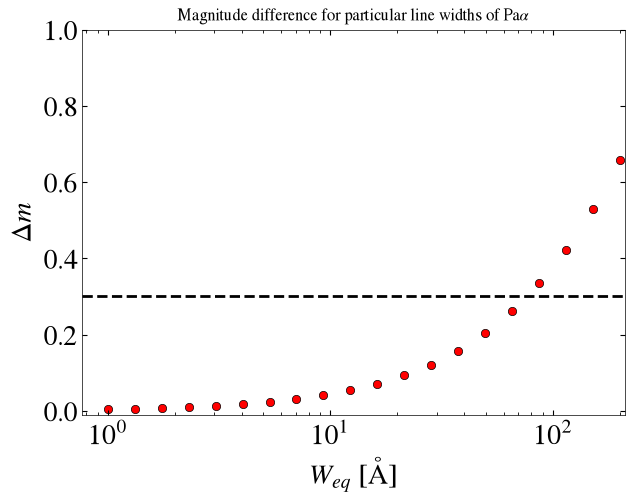

In [21]:

fig = plt.figure(figsize=(7, 5))
gs = gridspec.GridSpec(1, 1, figure=fig,  hspace=0.3, wspace=0.2)
ax = fig.add_subplot(gs[0, 0])

ax.scatter(W_eqs, mags, c='red', edgecolors='black', marker='o')
ax.set_ylabel(r'$\Delta m$')
ax.set_xlabel(r'$W_{eq}$ [Å]')
ax.axhline(0.3, ls='--', lw=2, c='black', label = r'$\Delta m$ = 0.3')
ax.set_xscale('log')
ax.set_xlim(0, 210)
ax.set_ylim(-.01, 1)

ax.set_title(r'Magnitude difference for particular line widths of Pa$\alpha$',)
plt.show()

In [ ]:
from sedfitter.sed import SEDCube
from synphot.models import Empirical1D

flux_path   = '/net/vdesk/data2/slagter/disc_models_robitaille_2017/sp--s-i/flux.fits'
seds        = SEDCube.read(flux_path)
sed         = seds.get_sed('cELn2Kfz_02')

x           = 200000*u.lyr * (0.046*u.arcsec).to(u.rad).value
ap_idx      = np.argmin((np.abs(x-sed.apertures)))

wave        = sed.wav 
flux        = sed.flux[ap_idx]

sp_disk_model = SourceSpectrum(Empirical1D, points=wave, lookup_table=flux)

to_run  = [(sp_disk_model, 'f187n', 'no_line')]
reports = {}
for sp, filter, mode in to_run:
    reports[filter + '_' + mode] = Observe_SED_with_1227_setting(sp_dngc346 = sp,
                                                                  filter= filter,
                                                                  d_new = 200000*u.lyr,
                                                                  d_old = 1*u.kpc ) #Double check this!
obs_modes = list(reports.keys()) 
print(reports[obs_modes[0]]['scalar']['total_exposure_time'])


171.78832


In [267]:
reports[obs_modes[0]]['scalar']['extracted_flux']

np.float64(1.6340356359983659)